In [1]:
#第三次作业
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
#1.1计算每个月的甲烷气候学数据，并将结果绘制在12个子图中。
#原始文件中xch4必须乘以10*9才能转换成ppb。文件中存在大量无效数据，计算时需要跳过缺失值不能当成0
ds = xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")
ds.info()

xarray.Dataset {
dimensions:
	time = 210 ;
	bnds = 2 ;
	lat = 36 ;
	lon = 72 ;
	pressure = 10 ;

variables:
	datetime64[ns] time_bnds(time, bnds) ;
		time_bnds:comment = time boundaries ;
	float64 lat_bnds(lat, bnds) ;
		lat_bnds:units = degrees_north ;
		lat_bnds:comment = latitude boundaries ;
	float64 lon_bnds(lon, bnds) ;
		lon_bnds:units = degrees_east ;
		lon_bnds:comment = longitude boundaries ;
	float64 pre(pressure) ;
		pre:standard_name = pressure ;
		pre:long_name = pressure ;
		pre:units = surface_pressure ;
		pre:axis = Z ;
		pre:comment = pressure center ;
	float64 pre_bnds(pressure, bnds) ;
		pre_bnds:units = surface_pressure ;
		pre_bnds:comment = pressure boundaries ;
	float64 land_fraction(lat, lon) ;
		land_fraction:standard_name = land_area_fraction ;
		land_fraction:long_name = land area fraction ;
		land_fraction:units = 1 ;
		land_fraction:comment = Land area fraction computed from GTOPO30 data available from the U.S. Geological Survey ;
	float32 xch4(time, lat, 


Data dimensions: (210, 36, 72)
Minimum XCH4: 1566.9854736328125 ppb
Maximum XCH4: 1999.4759521484375 ppb


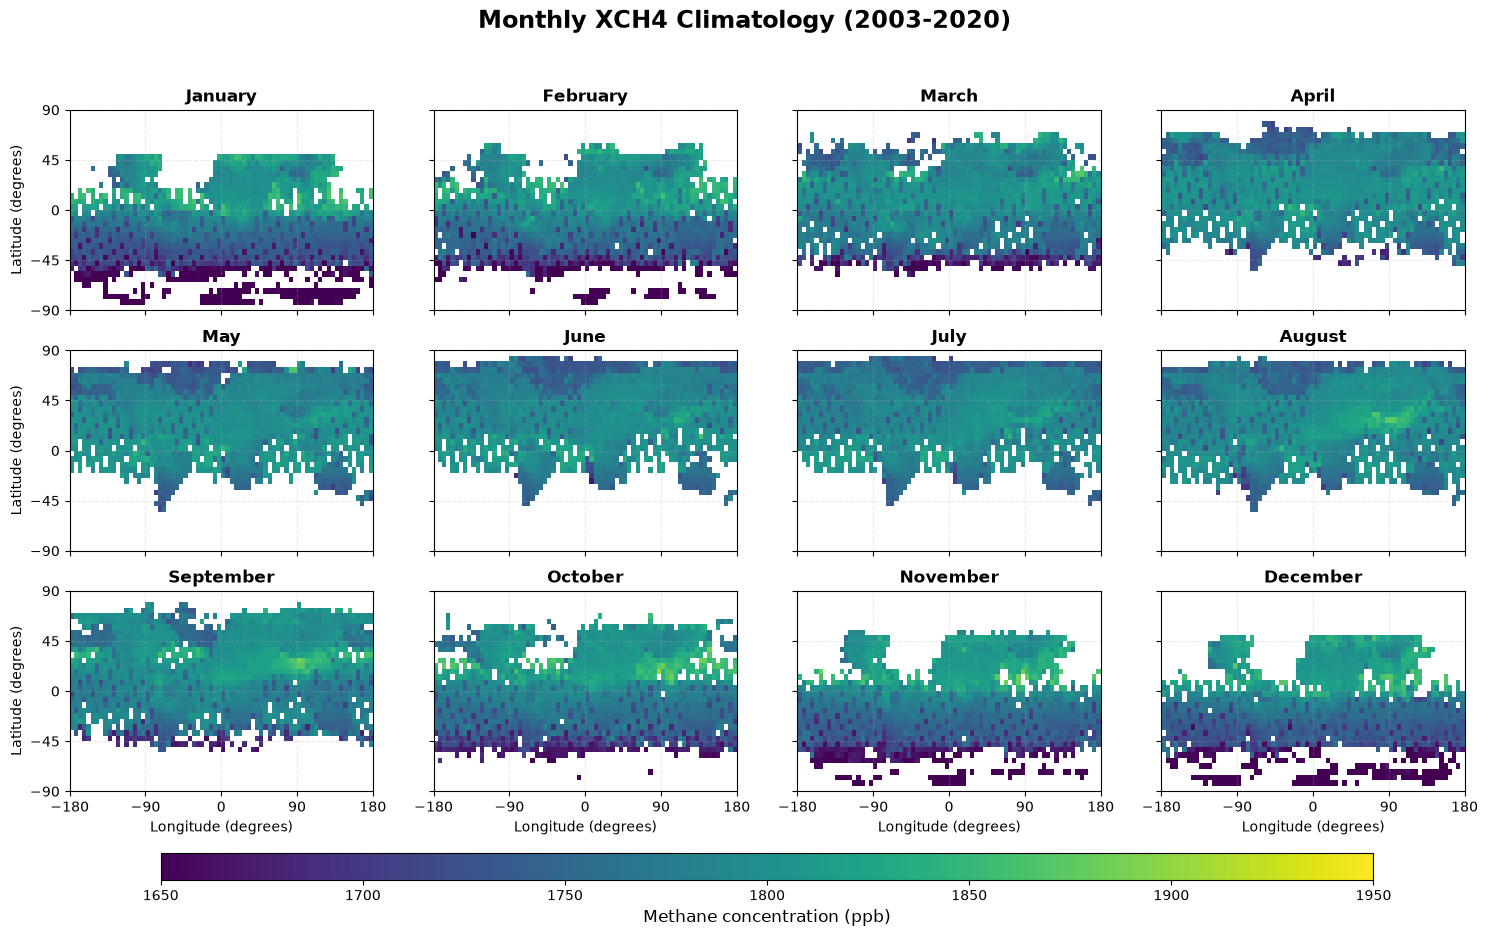

In [9]:
# 读取甲烷变量，筛选有效数据，剔除缺测值
xch4_raw = ds["xch4"]

# 原始单位为无量纲摩尔分数
xch4 = xch4_raw.where(np.isfinite(xch4_raw) & (xch4_raw > 0) & (xch4_raw < 1e-5))
# 转换为 ppb
xch4 = xch4 * 1e9
xch4.attrs["units"] = "ppb"
xch4 = xch4.load()
print("\nData dimensions:", xch4.shape)
print("Minimum XCH4:", float(xch4.min()), "ppb")
print("Maximum XCH4:", float(xch4.max()), "ppb")


# 将所有年份的同一个月份取平均
monthly_climatology = (xch4.groupby("time.month").mean(dim="time", skipna=True))
month_names = ["January", "February", "March", "April","May", "June", "July", "August","September", "October", "November", "December"]

fig, axes = plt.subplots(nrows=3,ncols=4,figsize=(18, 10),sharex=True,sharey=True)
vmin = 1650
vmax = 1950
for i, ax in enumerate(axes.flat):
    month_data = monthly_climatology.sel(month=i + 1)
    im = ax.pcolormesh(xch4["lon"],xch4["lat"],month_data,cmap="viridis",shading="auto",vmin=vmin,vmax=vmax)

    ax.set_title(month_names[i],fontsize=12,fontweight="bold")
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_yticks([-90, -45, 0, 45, 90])
    ax.grid(linestyle="--",alpha=0.25)
    if i // 4 == 2:
        ax.set_xlabel("Longitude (degrees)")
    if i % 4 == 0:
        ax.set_ylabel("Latitude (degrees)")

cbar = fig.colorbar(im,ax=axes.ravel().tolist(),orientation="horizontal",fraction=0.035,pad=0.08,aspect=45)

cbar.set_label("Methane concentration (ppb)",fontsize=12)

fig.suptitle("Monthly XCH4 Climatology (2003-2020)",fontsize=17,fontweight="bold",y=0.98)
plt.show()

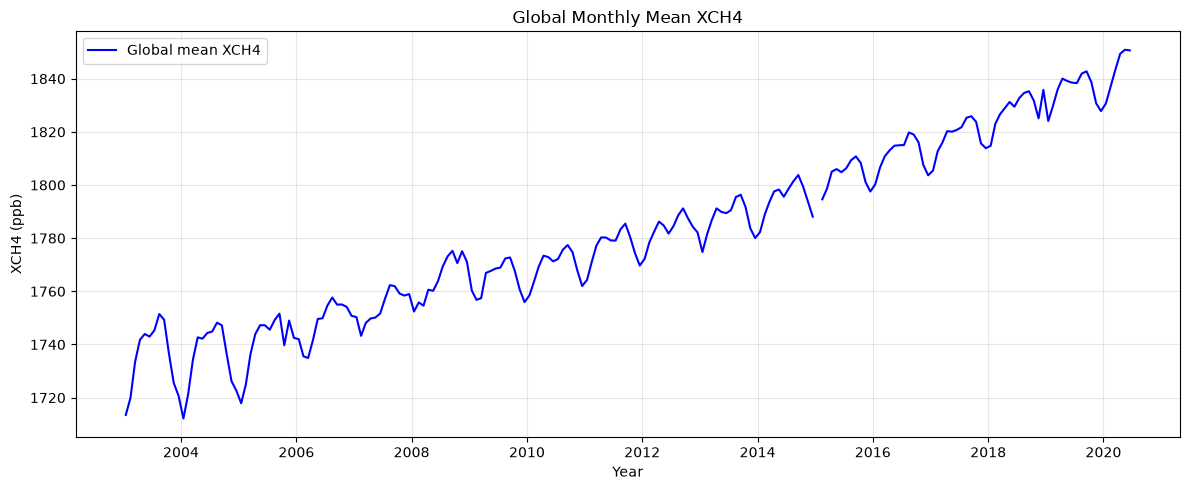

In [13]:
#1.2将2003-01至2020-06期间的全球平均甲烷浓度绘制为时间序列图。描述你的结果。将你的图与该图进行核对。
# 经纬度网格面积加权。AI建议我对于全球平均浓度使用维度面积加权平均而不是简单计算所有网格算术平均。
weights = np.cos(np.deg2rad(xch4.lat))
global_mean = xch4.weighted(weights).mean(dim=("lat", "lon"),skipna=True)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(global_mean.time,global_mean,color="b",linewidth=1.5,label="Global mean XCH4")
ax.set_title("Global Monthly Mean XCH4")
ax.set_xlabel("Year")
ax.set_ylabel("XCH4 (ppb)")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig("1_2_global_time_series.png",dpi=300)
plt.show()

#描述结果：甲烷浓度总体上升：从2003年初约1713.5 ppb上升至2020年6月约1850.7 ppb，表明长期甲烷浓度具有显著的增长趋势。存在年际波动：增长过程并不是完全线性的，部分年份的增长较慢，其他年份增长更快。存在月际波动：时间序列中有明显的上下起伏，可能与季节性变化以及卫星有效观测区域变化共同有关。


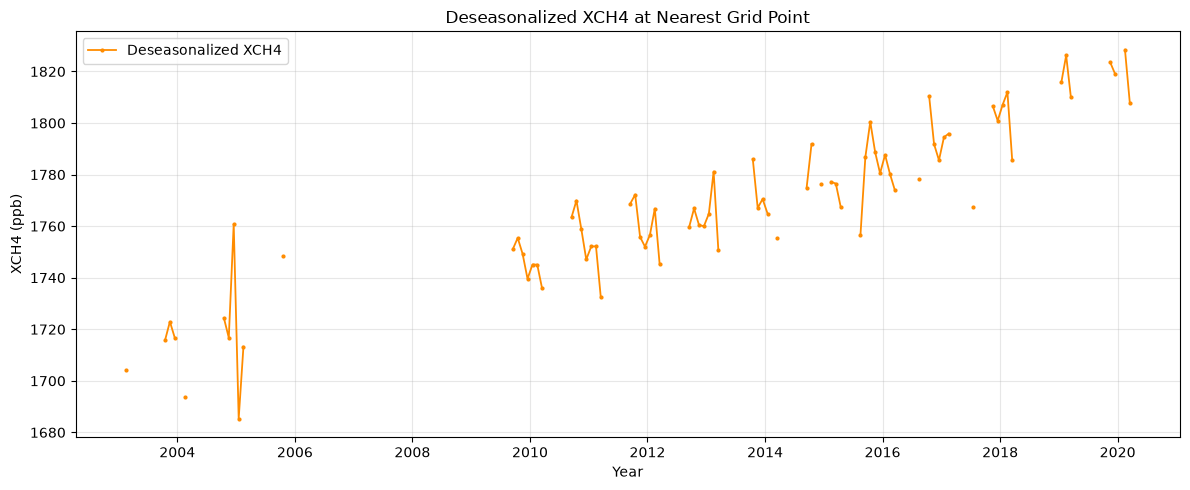

In [16]:
#1.3将2003年1月至2020年6月期间[南纬15°，西经150°]点的去季节化甲烷浓度绘制为时间序列图。描述你的结果。
#去季节化后，周期性起伏被消除，长期增长趋势更容易识别。
point = xch4.sel(lat=-15,lon=-150,method="nearest")
# 计算12个月各自的多年平均
monthly_clim = point.groupby("time.month").mean(dim="time",skipna=True)
anomaly = point.groupby("time.month") - monthly_clim

# 加回长期平均，保留浓度基准
deseasonalized = anomaly + point.mean(dim="time",skipna=True)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(deseasonalized.time,deseasonalized,".-",color="darkorange",linewidth=1.3,markersize=4,label="Deseasonalized XCH4")

ax.set_title("Deseasonalized XCH4 at Nearest Grid Point")
ax.set_xlabel("Year")
ax.set_ylabel("XCH4 (ppb)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("1_3_local_deseasonalized.png",dpi=300)
plt.show()
# 计算长期线性趋势
def calculate_trend(series):
    years = (series.time.dt.year+ (series.time.dt.month - 0.5) / 12).values
    values = series.values
    valid = np.isfinite(values)
    result = linregress(years[valid],values[valid])

    return result.slope

In [17]:
#去季节化后，甲烷浓度整体呈上升趋势，描述性线性拟合斜率约为6.23 ppb/年。相比原始数据，去季节化处理去除了由多年同月平均值定义的重复性季节信号，使长期变化趋势更易辨认。去季节化并不会自动消除随机噪声、观测误差或长期增长趋势，也不会填补缺失月份。

xarray.Dataset {
dimensions:
	time = 684 ;
	lat = 89 ;
	lon = 180 ;

variables:
	float32 sst(time, lat, lon) ;
		sst:pointwidth = 1.0 ;
		sst:valid_min = -3.0 ;
		sst:valid_max = 45.0 ;
		sst:units = degree_Celsius ;
		sst:long_name = Extended reconstructed sea surface temperature ;
		sst:standard_name = sea_surface_temperature ;
		sst:iridl:hasSemantics = iridl:SeaSurfaceTemperature ;
	float32 lat(lat) ;
		lat:standard_name = latitude ;
		lat:pointwidth = 2.0 ;
		lat:gridtype = 0 ;
		lat:units = degree_north ;
	float32 lon(lon) ;
		lon:standard_name = longitude ;
		lon:pointwidth = 2.0 ;
		lon:gridtype = 1 ;
		lon:units = degree_east ;
	datetime64[ns] time(time) ;

// global attributes:
	:Conventions = IRIDL ;
	:source = https://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCDC/.ERSST/.version3b/.sst/ ;
	:history = extracted and cleaned by Ryan Abernathey for Research Computing in Earth Science ;
}
SST dimensions: (684, 89, 180)
Latitude range: -88.0 88.0
Longitude range: 0.0 358.0

Niño 3.

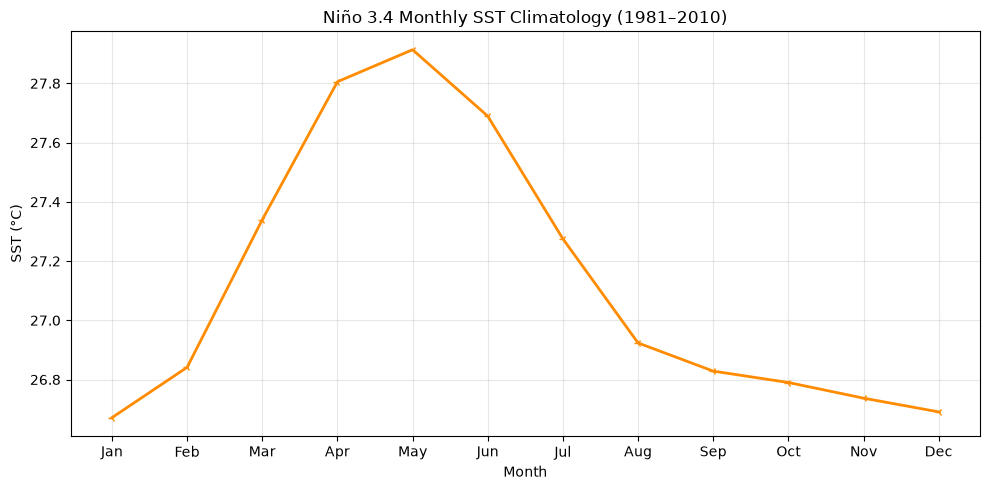

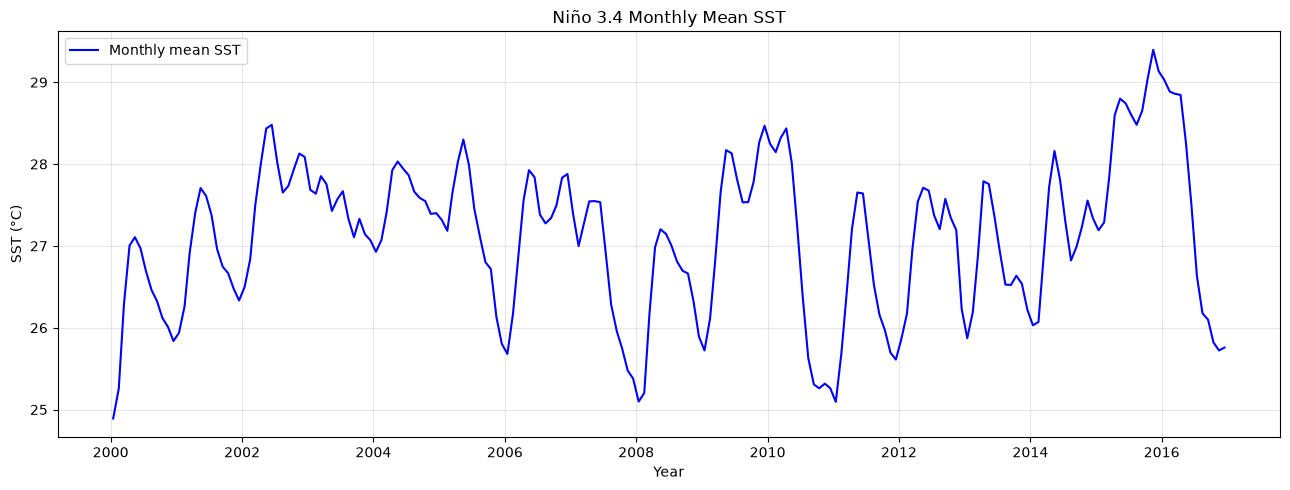

In [1]:
#尼诺3.4异常值可视为太平洋地区从国际日期变更线至南美洲海岸（北纬5°至南纬5°，西经170°至120°）这一带赤道海域海表温度（SST）的平均值。厄尔尼诺3.4指数通常采用3个月的滑动平均值，当厄尔尼诺3.4海域的海表温度在5个月或更长时间内超出±0.5°C时，即定义为厄尔尼诺或拉尼娜事件。有关厄尔尼诺3.4指数的更多信息，请参阅《赤道太平洋海表温度》。
#在本习题集中，您将使用来自美国国家海洋和大气管理局（NOAA）的海表温度（SST）数据。请下载 netCDF4 文件（NOAA_NCDC_ERSST_v3b_SST.nc）。
#2.1计算厄尔尼诺3.4区域海表温度的月平均气候值，并将该气候值从海表温度时间序列中减去，以获得异常值。
import os
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
ds = xr.open_dataset("NOAA_NCDC_ERSST_v3b_SST.nc")
ds.info()
if "sst" in ds.data_vars:
    sst = ds["sst"]
elif "SST" in ds.data_vars:
    sst = ds["SST"]
else:
    raise ValueError("SST variable not found.")
#规范一下坐标的名字
rename_dict = {}
for name in sst.dims:
    if name.lower() in ["latitude", "y"]:
        rename_dict[name] = "lat"
    elif name.lower() in ["longitude", "x"]:
        rename_dict[name] = "lon"
if rename_dict:
    sst = sst.rename(rename_dict)



sst = sst.squeeze(drop=True)
sst = sst.transpose("time", "lat", "lon")
#在这里统一一下单位，温度的开尔文或者摄氏度
units = str(sst.attrs.get("units", "")).lower().strip()

if units in ["k", "kelvin"]:
    sst = sst - 273.15


sst = sst.where(np.isfinite(sst) & (sst > -5) & (sst < 45))


sst = sst.assign_coords(lon=sst.lon % 360)
sst = sst.sortby("lat").sortby("lon")
print("\nSST dimensions:", sst.shape)
print("Latitude range:",
      float(sst.lat.min()),
      float(sst.lat.max()))
print("Longitude range:",
      float(sst.lon.min()),
      float(sst.lon.max()))



nino34_region = sst.sel(lat=slice(-5, 5),lon=slice(190, 240))

if (nino34_region.sizes["lat"] == 0 or nino34_region.sizes["lon"] == 0):
    raise ValueError("Niño 3.4 region selection failed.")

print("\nNiño 3.4 region:")
print(nino34_region)
#这里和上一个题目一样 用AI建议的纬度面积计算
weights = np.cos(np.deg2rad(nino34_region.lat))

nino34_sst = nino34_region.weighted(weights).mean(dim=("lat", "lon"),skipna=True)
print("\nMonthly Niño 3.4 SST:")
print(nino34_sst)

#2.1
baseline = nino34_sst.sel(time=slice("1981-01-01", "2010-12-31"))

if baseline.sizes["time"] == 0:
    raise ValueError("No data in 1981–2010. ""Check the dataset time coverage.")

monthly_climatology = baseline.groupby("time.month").mean(dim="time",skipna=True)

sst_anomaly = (nino34_sst.groupby("time.month") - monthly_climatology)

sst_anomaly_3m = sst_anomaly.rolling(time=3,center=True,min_periods=3).mean()
print("\nMonthly SST climatology:")
print(monthly_climatology)
print("\nSST anomalies:")
print(sst_anomaly)

months = ["Jan", "Feb", "Mar", "Apr","May", "Jun", "Jul", "Aug","Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, 13),monthly_climatology.values,color="darkorange",marker="3",linewidth=2)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(months)
ax.set_xlabel("Month")
ax.set_ylabel("SST (°C)")
ax.set_title("Niño 3.4 Monthly SST Climatology (1981–2010)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

sst_plot = nino34_sst.sel(time=slice("2000-01-01", "2020-12-31"))
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(sst_plot.time.values,sst_plot.values,color="b",linewidth=1.5,label="Monthly mean SST")
ax.set_title("Niño 3.4 Monthly Mean SST")
ax.set_xlabel("Year")
ax.set_ylabel("SST (°C)")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()



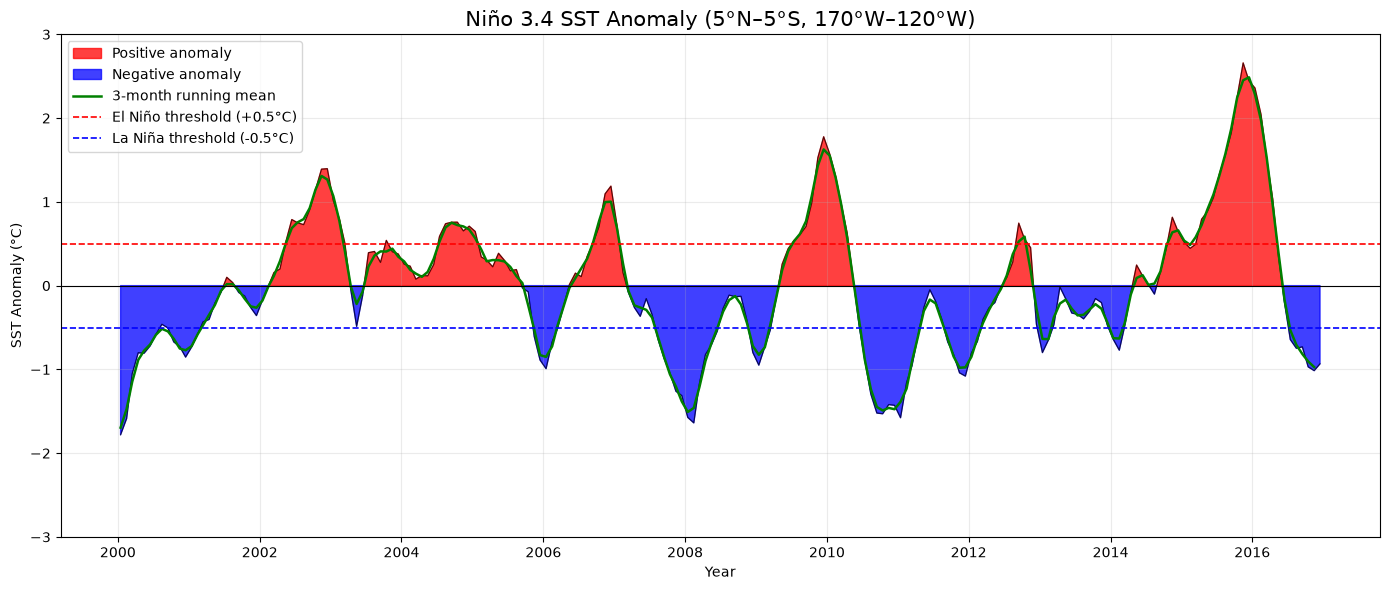

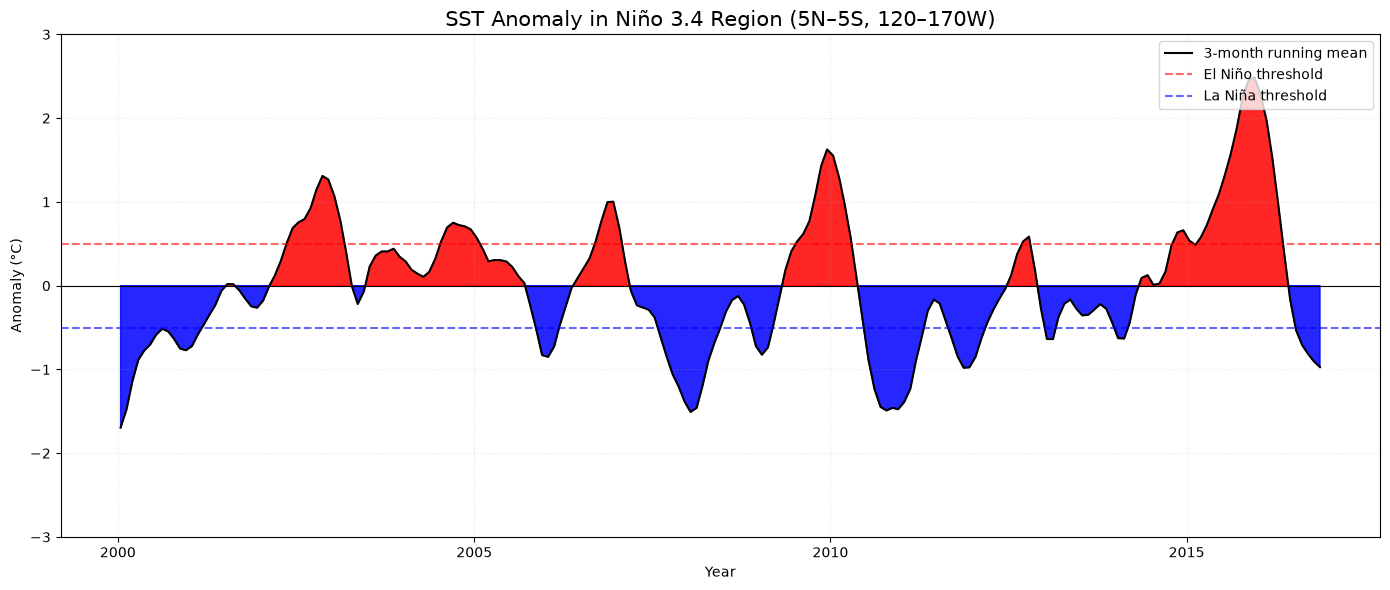


Niño 3.4 SST Analysis Summary
Climatology baseline: 1981–2010
Analysis period: 2000–2020
Maximum 3-month SST anomaly: 2.487 °C
Date of maximum: 2015-12
Minimum 3-month SST anomaly: -1.695 °C
Date of minimum: 2000-01

Analysis completed.


In [4]:
#2.2可视化计算得到的厄尔尼诺3.4数据。你的图表应与下图类似。
#再给出的参考图里面可以知道，红色代表正海温异常，蓝色代表负海温异常，黑线表示三个月滑动平均。两条虚线代表+-0.5℃的阈值。所以需要画多个图叠加在一起。
anomaly_plot = sst_anomaly.sel(time=slice("2000-01-01", "2020-12-31"))
smooth_plot = sst_anomaly_3m.sel(time=slice("2000-01-01", "2020-12-31"))
time = pd.to_datetime(anomaly_plot.time.values)
values = anomaly_plot.values
smooth_values = smooth_plot.values
fig, ax = plt.subplots(figsize=(14, 6))

ax.fill_between(time,0,values,where=(values >= 0),color="r",alpha=0.75,interpolate=True,label="Positive anomaly")
ax.fill_between(time,0,values,where=(values < 0),color="b",alpha=0.75,interpolate=True,label="Negative anomaly")
ax.plot(time,values,color="black",linewidth=0.8,alpha=0.7)
ax.plot(time,smooth_values,color="g",linewidth=1.8,label="3-month running mean")

ax.axhline(0.5,color="r",linestyle="--",linewidth=1.2,label="El Niño threshold (+0.5°C)")
ax.axhline(-0.5,color="b",linestyle="--",linewidth=1.2,label="La Niña threshold (-0.5°C)")

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Niño 3.4 SST Anomaly (5°N–5°S, 170°W–120°W)",fontsize=15)
ax.set_xlabel("Year")
ax.set_ylabel("SST Anomaly (°C)")
ax.set_ylim(-3, 3)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(alpha=0.25)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 6))

ax.fill_between(time,0,smooth_values,where=(smooth_values >= 0),color="r",alpha=0.85,interpolate=True)
ax.fill_between(time,0,smooth_values,where=(smooth_values < 0),color="b",alpha=0.85,interpolate=True)

ax.plot(time,smooth_values,color="black",linewidth=1.5,label="3-month running mean")

ax.axhline(0.5,color="r",linestyle="--",alpha=0.6,label="El Niño threshold")
ax.axhline(-0.5,color="b",linestyle="--",alpha=0.6,label="La Niña threshold")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("SST Anomaly in Niño 3.4 Region (5N–5S, 120–170W)",fontsize=15)
ax.set_xlabel("Year")
ax.set_ylabel("Anomaly (°C)")
ax.set_ylim(-3, 3)

ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(linestyle=":", alpha=0.3)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

smooth_series = pd.Series(sst_anomaly_3m.values,index=pd.to_datetime(sst_anomaly_3m.time.values))
smooth_series = smooth_series.loc["2000-01-01":"2020-12-31"]

monthly_index = pd.date_range(start="2000-01-01",end="2020-12-01",freq="MS")

smooth_series.index = smooth_series.index.to_period("M").to_timestamp()
smooth_series = smooth_series.reindex(monthly_index)
#总结一下
valid_anomaly = smooth_series.dropna()
print("\n==========================================")
print("Niño 3.4 SST Analysis Summary")
print("==========================================")
print("Climatology baseline: 1981–2010")
print("Analysis period: 2000–2020")
print("Maximum 3-month SST anomaly:",round(valid_anomaly.max(), 3),"°C")
print("Date of maximum:",valid_anomaly.idxmax().strftime("%Y-%m"))
print("Minimum 3-month SST anomaly:",round(valid_anomaly.min(), 3),"°C")
print("Date of minimum:",valid_anomaly.idxmin().strftime("%Y-%m"))
ds.close()
print("\nAnalysis completed.")


xarray.Dataset {
dimensions:
	time = 210 ;
	bnds = 2 ;
	lat = 36 ;
	lon = 72 ;
	pressure = 10 ;

variables:
	datetime64[ns] time_bnds(time, bnds) ;
		time_bnds:comment = time boundaries ;
	float64 lat_bnds(lat, bnds) ;
		lat_bnds:units = degrees_north ;
		lat_bnds:comment = latitude boundaries ;
	float64 lon_bnds(lon, bnds) ;
		lon_bnds:units = degrees_east ;
		lon_bnds:comment = longitude boundaries ;
	float64 pre(pressure) ;
		pre:standard_name = pressure ;
		pre:long_name = pressure ;
		pre:units = surface_pressure ;
		pre:axis = Z ;
		pre:comment = pressure center ;
	float64 pre_bnds(pressure, bnds) ;
		pre_bnds:units = surface_pressure ;
		pre_bnds:comment = pressure boundaries ;
	float64 land_fraction(lat, lon) ;
		land_fraction:standard_name = land_area_fraction ;
		land_fraction:long_name = land area fraction ;
		land_fraction:units = 1 ;
		land_fraction:comment = Land area fraction computed from GTOPO30 data available from the U.S. Geological Survey ;
	float32 xch4(time, lat, 

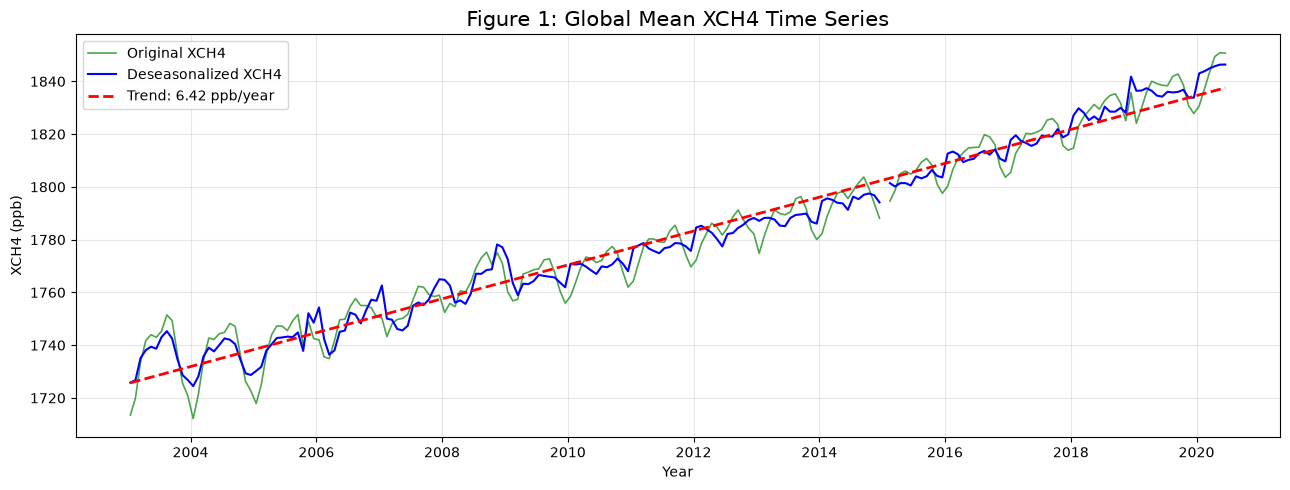

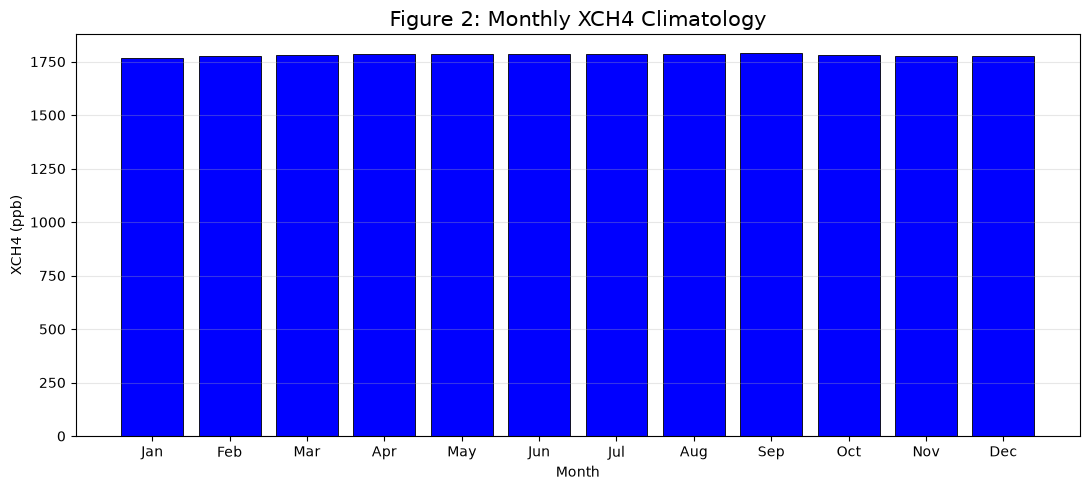

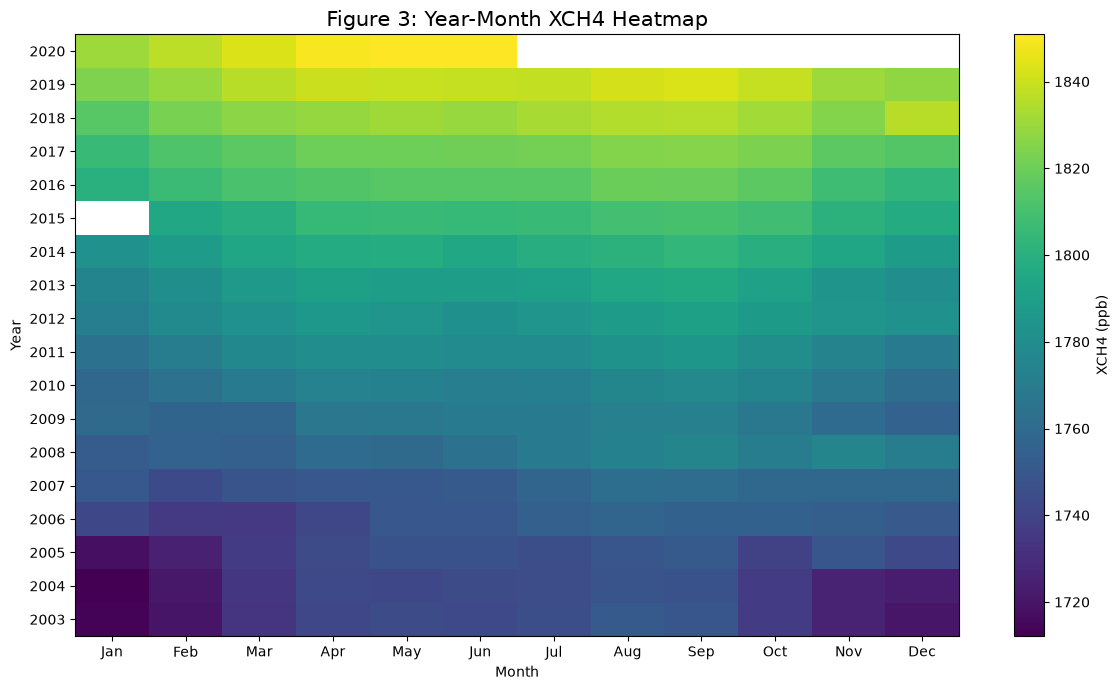

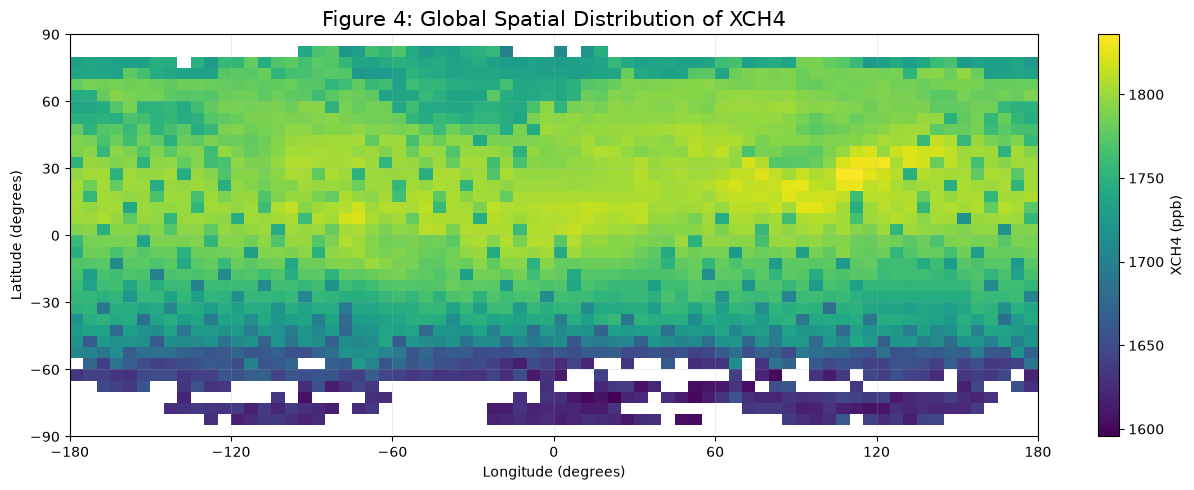

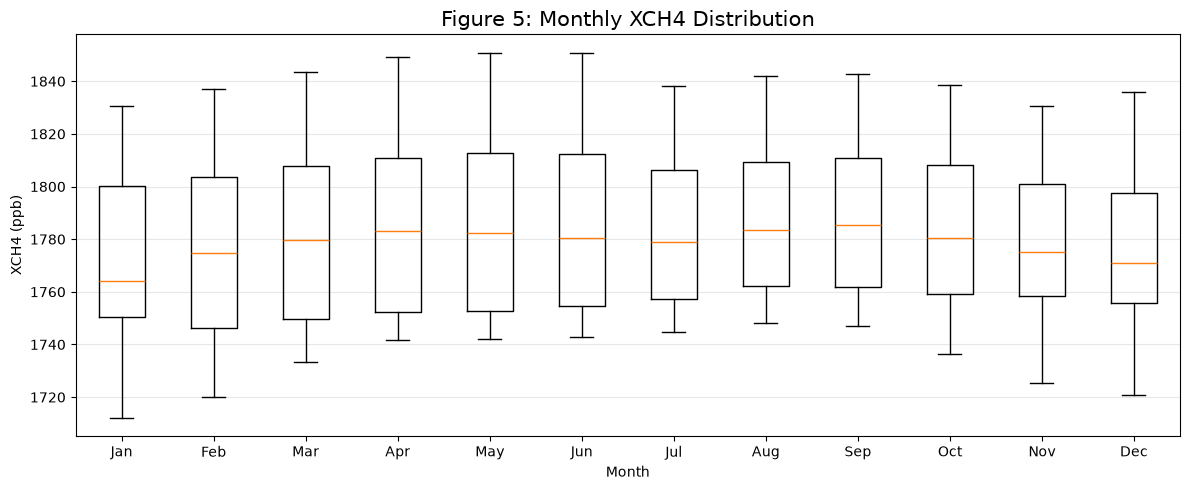

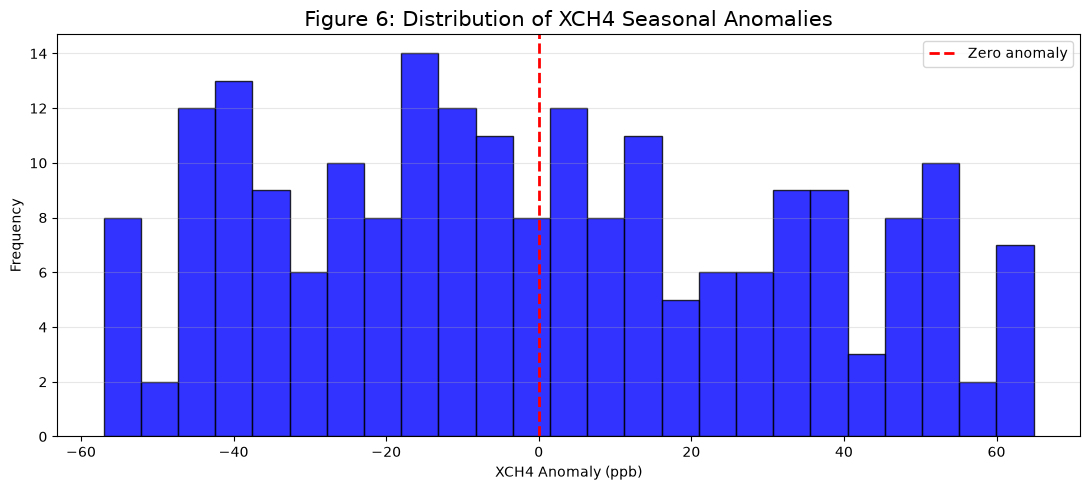


Global Methane Analysis Summary
Valid months: 209
Mean XCH4: 1781.52 ppb
Minimum XCH4: 1712.15 ppb
Maximum XCH4: 1850.89 ppb
Deseasonalized trend: 6.42 ppb/year

Analysis completed.


In [7]:
#浏览美国宇航局戈达德地球科学数据与信息服务中心（GES DISC）的网站。搜索并下载你感兴趣的数据集。你也可以在本次习题中使用本小组的数据。但数据集应为 netCDF 格式，并包含时间信息。
#我选择用甲烷的数据，包含时间经纬度和甲烷浓度变量，并且也经过了数据核查。
#3.1绘制某个变量的时序图，并去除其中的月度季节周期。
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import linregress
ds = xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")
ds.info()
raw = ds["xch4"]
xch4 = raw.where(np.isfinite(raw) &(raw > 0) &(raw < 1e-5)) * 1e9
xch4 = xch4.load()
print("\nData dimensions:", xch4.shape)

weights = np.cos(np.deg2rad(xch4.lat))
global_mean = xch4.weighted(weights).mean(dim=("lat", "lon"),skipna=True)
print("\nGlobal mean XCH4:")
print(global_mean)

#3.1
monthly_clim = global_mean.groupby("time.month").mean(dim="time",skipna=True)
seasonal_anomaly = (global_mean.groupby("time.month") - monthly_clim)
deseasonalized = (seasonal_anomaly + global_mean.mean(dim="time", skipna=True))

years = ((global_mean.time.dt.year) + (global_mean.time.dt.month - 0.5) / 12).values
values = deseasonalized.values
valid = np.isfinite(values)
regression = linregress(years[valid],values[valid])
trend = (regression.intercept + regression.slope * years)
print("\nLinear trend:")
print(round(regression.slope, 3), "ppb/year")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(global_mean.time,global_mean,color="g",linewidth=1.2,alpha=0.7,label="Original XCH4")
ax.plot(deseasonalized.time,deseasonalized,color="b",linewidth=1.5,label="Deseasonalized XCH4")
ax.plot(global_mean.time,trend,color="r",linestyle="--",linewidth=2,label=f"Trend: {regression.slope:.2f} ppb/year")
ax.set_title("Figure 1: Global Mean XCH4 Time Series",fontsize=15)
ax.set_xlabel("Year")
ax.set_ylabel("XCH4 (ppb)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

#3.2
months = ["Jan", "Feb", "Mar", "Apr","May", "Jun", "Jul", "Aug","Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(range(1, 13),monthly_clim.values,color="b",edgecolor="black",linewidth=0.6)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(months)
ax.set_title("Figure 2: Monthly XCH4 Climatology",fontsize=15)
ax.set_xlabel("Month")
ax.set_ylabel("XCH4 (ppb)")
ax.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.show()

series = pd.Series(global_mean.values,index=pd.to_datetime(global_mean.time.values))

heatmap_data = series.groupby([series.index.year, series.index.month]).mean().unstack(level=1)
heatmap_data = heatmap_data.reindex(columns=range(1, 13))
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(heatmap_data.values,aspect="auto",origin="lower",cmap="viridis")
ax.set_xticks(range(12))
ax.set_xticklabels(months)
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)
ax.set_title("Figure 3: Year-Month XCH4 Heatmap",fontsize=15)
ax.set_xlabel("Month")
ax.set_ylabel("Year")
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("XCH4 (ppb)")
plt.tight_layout()
plt.show()

spatial_mean = xch4.mean(dim="time",skipna=True)
fig, ax = plt.subplots(figsize=(13, 5))
im = ax.pcolormesh(xch4.lon,xch4.lat,spatial_mean,cmap="viridis",shading="auto")
ax.set_title("Figure 4: Global Spatial Distribution of XCH4",fontsize=15)
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
ax.set_xticks([-180, -120, -60, 0, 60, 120, 180])
ax.set_yticks([-90, -60, -30, 0, 30, 60, 90])
ax.grid(alpha=0.2)
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("XCH4 (ppb)")
plt.tight_layout()
plt.show()


monthly_values = [series.loc[series.index.month == m].dropna().values for m in range(1, 13)]
fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(monthly_values,tick_labels=months,showfliers=True)
ax.set_title("Figure 5: Monthly XCH4 Distribution",fontsize=15)
ax.set_xlabel("Month")
ax.set_ylabel("XCH4 (ppb)")
ax.grid(axis="y",alpha=0.3)
plt.tight_layout()
plt.show()



anomaly_values = seasonal_anomaly.values
anomaly_values = anomaly_values[np.isfinite(anomaly_values)]
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(anomaly_values,bins=25,color="b",edgecolor="black",alpha=0.8)
ax.axvline(0,color="red",linestyle="--",linewidth=2,label="Zero anomaly")

ax.set_title("Figure 6: Distribution of XCH4 Seasonal Anomalies",fontsize=15)
ax.set_xlabel("XCH4 Anomaly (ppb)")
ax.set_ylabel("Frequency")
ax.grid(axis="y",alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


print("\n====================================")
print("Global Methane Analysis Summary")
print("====================================")

print("Valid months:",int(np.isfinite(global_mean.values).sum()))
print("Mean XCH4:",round(float(global_mean.mean(skipna=True)), 2),"ppb")
print("Minimum XCH4:",round(float(global_mean.min(skipna=True)), 2),"ppb")
print("Maximum XCH4:",round(float(global_mean.max(skipna=True)), 2),"ppb")
print("Deseasonalized trend:",round(regression.slope, 3),"ppb/year")
ds.close()
print("\nAnalysis completed.")
